## Interpolation ##
Here, I demonstrate how to interpolate a flux in a given band (e.g. SDSS r-band) based on other available observations. For the purposes of this tutorial, I will use an artificial SED produced by CIGALE for a real galaxy from my previous paper, Lisiecki et al. (2026a). I convolve the SED with the transmission curves and assume an error of a few percent to emulate the observations. You can modify the redshift, available observations and interpolation target to see how does the algorythm work for specific cases.

The fundamental assumption of my method is that the SED of a galaxy within a narrow range can be estimated as Flam = Lam^β. This is true, as long as we are in UV part (120-300nm) or optical-NIR par Taking the transmission curves (TCs) into account, I then find the underlying SED and convolve it with the target-band TC. Finally, I rerun the estimate within a Monte Carlo framework to calculate the error bars. This notebook presents the method.

At the end of the file you can find How-To cell with a real GNUAstro radial profiles and comparison with metodology introduced by Buitrago+17. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits, ascii
import json, os
from scipy.optimize import brentq

In [2]:
from mainFunctions import *

In [3]:
databaseBands = cigale_filters()

We have to define the bands we have and the target bands. I took the database from the CIGALE itself, so the structure is the same, it goes like this:

telescopeName.mainInstrument.specificInstrument(if needed).bandName

If one wants to know the available bands and their names, use findBandByName function.

In [4]:
findBandByName('sdss',databaseBands)

array(['sloan.sdss.u', 'sloan.sdss.g', 'sloan.sdss.r', 'sloan.sdss.i',
       'sloan.sdss.z'], dtype='<U25')

In [5]:
bandsAvailable = ['jwst.nircam.F480M','jwst.nircam.F460M','jwst.nircam.F444W','jwst.nircam.F430M',
                 'jwst.nircam.F410M','jwst.nircam.F356W','jwst.nircam.F335M','jwst.nircam.F300M',
                 'jwst.nircam.F277W','jwst.nircam.F250M','jwst.nircam.F210M','jwst.nircam.F200W',
                 'jwst.nircam.F182M','jwst.nircam.F162M','jwst.nircam.F150W','jwst.nircam.F115W',
                 'jwst.nircam.F090W','jwst.nircam.F070W','hst.acs.hrc.F850LP','hst.acs.wfc.F814W',
                 'hst.acs.wfc.F775W','hst.acs.wfc.F606W','hst.acs.wfc.F435W','hst.wfc3.uvis.F336W',
                 'hst.wfc3.uvis.F275W','hst.wfc3.uvis.F225W']  # this is list of filters you want to use 
toInterpolate = ['sloan.sdss.r']
# this is a list of filters you want to find
redshift = 0.525

I could not find hst.acs.hrc.F850LP is not in the database, it will be skipped
Check the spelling or download it from SVO


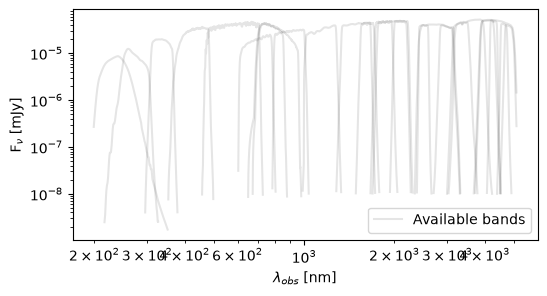

In [6]:
fig = plt.figure(figsize = (6,3))
ax = plt.subplot(111)
# loading the transmission curves
bandsAvailable = loadTransmissionCurves(bandsAvailable)
toInterpolate = loadTransmissionCurves(toInterpolate)
wavelengthAvailable = {}
for b in bandsAvailable:
    tc = bandsAvailable[b]
    w = np.average(tc[:,0],weights=tc[:,1])
    ax.plot(tc[:,0]/10, tc[:,1]*1e-4, c = 'k', alpha = 0.1)
    wavelengthAvailable[b] = float(w/10)
ax.plot([],[], c = 'k', alpha = 0.1, label = 'Available bands')
ax.set_xlabel('$\\lambda_{obs}$ [nm]')
ax.set_ylabel('F$_\\nu$ [mJy]')
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend()

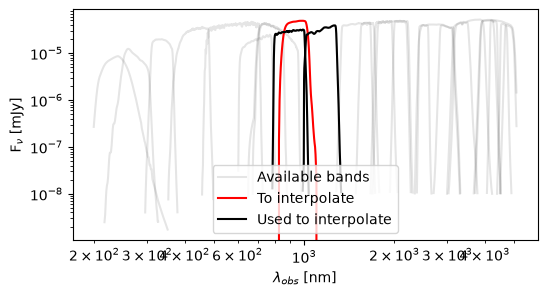

In [7]:
# finding shorter and longer lambda-bands
short = {}
long = {}
wavelengthInterpolated = {}
for b in toInterpolate:
    tc = toInterpolate[b]
    w = np.average(tc[:,0],weights=tc[:,1])*(1+redshift)/10
    ax.plot(tc[:,0]*(1+redshift)/10, tc[:,1]*1e-4, c = 'r', alpha = 1)
    wavelengthInterpolated[b] = w
    #### Find shorter lambda ####
    indx = np.where(list(wavelengthAvailable.values()) < w)[0]
    shorter = np.array(list(wavelengthAvailable.keys()))[indx]
    indx = np.where(np.array(list(wavelengthAvailable.values()))[indx] ==
                       np.max(np.array(list(wavelengthAvailable.values()))[indx]))[0]
    shorter = shorter[indx][0]
    tc = bandsAvailable[shorter]
    ax.plot(tc[:,0]/10, tc[:,1]*1e-4, c = 'k', alpha = 1)
    #### Find longer lambda ####
    indx = np.where(list(wavelengthAvailable.values()) > w)[0]
    longer = np.array(list(wavelengthAvailable.keys()))[indx]
    indx = np.where(np.array(list(wavelengthAvailable.values()))[indx] ==
                       np.min(np.array(list(wavelengthAvailable.values()))[indx]))[0]
    longer = longer[indx][0]
    tc = bandsAvailable[longer]
    ax.plot(tc[:,0]/10, tc[:,1]*1e-4, c = 'k', alpha = 1)
    short[b] = shorter
    long[b] = longer
ax.plot([],[], c = 'r', alpha = 1, label = 'To interpolate')
ax.plot([],[], c = 'k', alpha = 1, label = 'Used to interpolate')
ax.legend()
fig

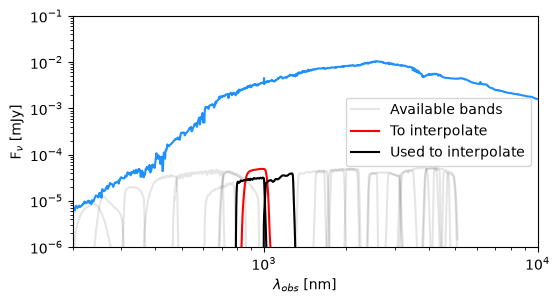

In [8]:
SED = fits.open('Uncertainties/6319.0_best_model.fits')[1].data
lam = SED['wavelength']
Fnu = SED['Fnu']
ax.plot(lam, Fnu, c = 'dodgerblue')
ax.set_xlim(2e2, 1e4)
ax.set_ylim(1e-6, 1e-1)
fig

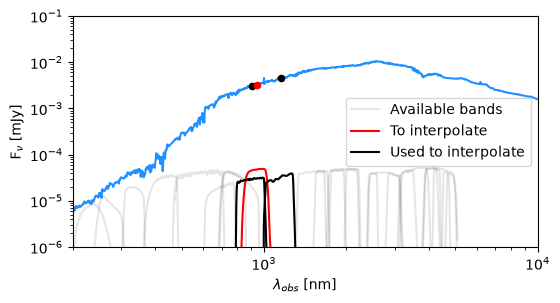

In [9]:
for b in toInterpolate:
    _, yshort = convolveFilterWithSED(lam, Fnu, bandsAvailable[short[b]])
    _, ylong = convolveFilterWithSED(lam, Fnu, bandsAvailable[long[b]])
    ax.scatter([wavelengthAvailable[short[b]], wavelengthAvailable[long[b]]], 
               [yshort, ylong], c = 'k', s = 20, zorder = 4)
    fnu, fnuErr = predictFnu_MC(yshort, ylong,yshort*0.08, ylong*0.03,
                      bandsAvailable[short[b]],
                      bandsAvailable[long[b]],
                      toInterpolate[b],
                      redshift,n_iter=1000)
    
    ax.scatter(wavelengthInterpolated[b], [fnu], c = 'r', s = 20, zorder = 4)
    _,y = convolveFilterWithSED(lam, Fnu, toInterpolate[b], redshift =redshift)
fig

In [10]:
print('model flux = %.3f + %.3f - %.3f [uJy]'%(fnu*1e3, fnuErr[0]*1e3, fnuErr[1]*1e3))
print('model flux minus real flux = %.3f [uJy]'%(fnu*1e3-y*1e3))
print('model flux over real flux = %.3f'%(fnu/y))
print('flux over error [model] = +%.3f-%.3f sigma'%(fnu/fnuErr[0], fnu/fnuErr[1]))

model flux = 3.251 + 0.212 - 0.212 [uJy]
model flux minus real flux = -0.045 [uJy]
model flux over real flux = 0.986
flux over error [model] = +15.332-15.301 sigma


In [11]:
# Define a dictionary with available radial profiles
bandsAvailablePaths = {'jwst.nircam.F444W': 'ceers_11225/f444w/radial_FINAL_MSK.txt',
                       'jwst.nircam.F410M': 'ceers_11225/f410m/radial_FINAL_MSK.txt',
                       'jwst.nircam.F356W': 'ceers_11225/f356w/radial_FINAL_MSK.txt',
                       'jwst.nircam.F277W': 'ceers_11225/f277w/radial_FINAL_MSK.txt',
                       'jwst.nircam.F200W': 'ceers_11225/f200w/radial_FINAL_MSK.txt',
                       'jwst.nircam.F150W': 'ceers_11225/f150w/radial_FINAL_MSK.txt',
                       'jwst.nircam.F115W': 'ceers_11225/f115w/radial_FINAL_MSK.txt'}
# Define a list of bands to interpolate
toInterpolate = ['sloan.sdss.i','sloan.sdss.z']
redshift = 0.773
fluxColumn = 'SIGCLIP_MEAN'
fluxColumnErr = 'SIGCLIP_STD'
# Find the interpolated profiles (it also saves the results)
result = GNUAstroImplementation(bandsAvailablePaths,
                       toInterpolate,
                       redshift,
                       fluxColumn,
                       fluxColumnErr,
                       'ceers_11225/interpolated.fits')

In [12]:
i_Buitrago = ascii.read('ceers_11225/i_sdss/radial_FINAL_MSK.txt')
z_Buitrago = ascii.read('ceers_11225/z_sdss/radial_FINAL_MSK.txt')

(0.001, 2)

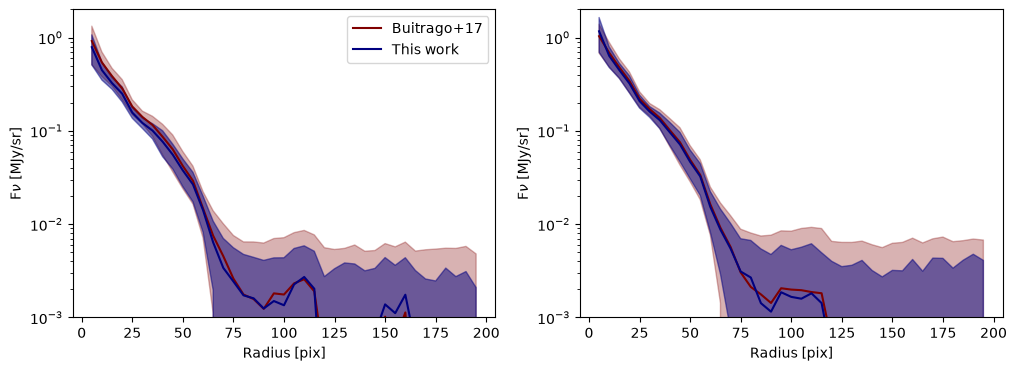

In [13]:
fig = plt.figure(figsize=(12,4))
plt.subplot(121)
plt.plot(i_Buitrago['col1'], i_Buitrago['col3'], c = 'maroon', label = 'Buitrago+17')
plt.fill_between(i_Buitrago['col1'], 
                 i_Buitrago['col3']+i_Buitrago['col5'], 
                 i_Buitrago['col3']-i_Buitrago['col5'],color = 'maroon', alpha = 0.3)
plt.plot(i_Buitrago['col1'], result['sloan.sdss.i'], c = 'navy', label = 'This work')
plt.fill_between(i_Buitrago['col1'], 
                 result['sloan.sdss.i']+result['sloan.sdss.i_err'], 
                 result['sloan.sdss.i']-result['sloan.sdss.i_err'],color = 'navy', alpha = 0.5)
plt.yscale('log')
plt.xlabel('Radius [pix]')
plt.ylabel('F$\\nu$ [MJy/sr]')
plt.ylim(1e-3, 2)
plt.legend()

plt.subplot(122)
plt.plot(z_Buitrago['col1'], z_Buitrago['col3'], c = 'maroon', label = 'Buitrago+17')
plt.fill_between(z_Buitrago['col1'], 
                 z_Buitrago['col3']+z_Buitrago['col5'], 
                 z_Buitrago['col3']-z_Buitrago['col5'],color = 'maroon', alpha = 0.3)
plt.plot(z_Buitrago['col1'], result['sloan.sdss.z'], c = 'navy', label = 'This work')
plt.fill_between(z_Buitrago['col1'], 
                 result['sloan.sdss.z']+result['sloan.sdss.z_err'], 
                 result['sloan.sdss.z']-result['sloan.sdss.z_err'],color = 'navy', alpha = 0.5)
plt.yscale('log')
plt.xlabel('Radius [pix]')
plt.ylabel('F$\\nu$ [MJy/sr]')
plt.ylim(1e-3, 2)